# 23 - Flyback Medio: Fixed vs Variable + Estresse

Este notebook compara o **mesmo conversor em modelo medio** com:
- `fixed step`
- `variable step`

E roda uma campanha de estresse para medir:
- taxa de convergencia
- tempo total
- numero de passos
- rejeicoes de passo

> Nota: aqui usamos **modelo medio (sem chaveamento explicito)** para isolar o comportamento dos modos de integracao.


In [1]:
import time
import statistics

import numpy as np
import matplotlib.pyplot as plt

import pulsim as p

print("Pulsim:", p.__version__)

Pulsim: 2.0.0


## 1) Parametros do conversor

Ajuste os parametros abaixo para deixar os casos mais leves ou mais pesados.


In [2]:
CONVERTER_ID = "flyback_avg"

VIN = 24.0
DUTY = 0.36
TURNS_RATIO = 1.8
L_MAIN = 120e-6
C_MAIN = 150e-6
R_LOAD = 10.0
RC_SECTIONS = 12

# Perfil de estresse
# Se quiser acelerar para smoke test: STRESS_HEAVY = False
STRESS_HEAVY = True

BASE_TSTOP = 0.020 if STRESS_HEAVY else 0.006
BASE_DT_FIXED = 5e-7 if STRESS_HEAVY else 1e-6

print("Conversor:", CONVERTER_ID)
print("BASE_TSTOP:", BASE_TSTOP)
print("BASE_DT_FIXED:", BASE_DT_FIXED)


Conversor: flyback_avg
BASE_TSTOP: 0.02
BASE_DT_FIXED: 5e-07


## 2) Circuito equivalente (modelo medio)

Para manter comparacao limpa entre `fixed` e `variable`, o circuito usa fonte equivalente + rede passiva de alta ordem.


In [3]:
def equivalent_output_voltage(vin: float, duty: float, turns_ratio: float = 1.0) -> float:
    duty = float(np.clip(duty, 1e-4, 0.95))
    return vin * turns_ratio * duty / max(1e-4, (1.0 - duty))


def build_circuit(vin: float, duty: float, turns_ratio: float, L_main: float, C_main: float, R_load: float, rc_sections: int = 8):
    # v2: CircuitBuilder + string node names ("gnd" is ground).
    b = p.CircuitBuilder()
    v_eq = equivalent_output_voltage(vin, duty, turns_ratio)
    b.add_voltage_source("Veq", "src", "gnd", v_eq)

    # Dinamica principal
    b.add_inductor("L_main", "src", "out", L_main)
    b.add_capacitor("C_main", "out", "gnd", C_main)
    b.add_resistor("R_load", "out", "gnd", R_load)

    # Rede RC extra para aumentar ordem e rigidez numerica
    prev = "out"
    for k in range(int(rc_sections)):
        nrc = f"rc_{k}"
        b.add_resistor(f"Rrc_{k}", prev, nrc, 0.12 + 0.03 * k)
        b.add_capacitor(f"Crc_{k}", nrc, "gnd", 8.2e-6 / (1.0 + 0.22 * k))
        prev = nrc

    # Carga auxiliar para evitar nos muito frouxos
    b.add_resistor("R_aux", prev, "gnd", max(8.0, R_load * 0.8))

    return b, {"n_out": "out", "v_eq": v_eq}


## 3) Configuracao de solver

Regras usadas:
- `fixed`: `p.simulate(b, t_end=, dt=)` — motor `pwl` de passo fixo
  (companheiro trapezoidal), passo estrito `dt`
- `variable`: `p.run_transient_adaptive(...)` — driver Python que roda
  segmentos de `dt` constante e ajusta `dt` pela taxa de variacao do
  estado (sem estimativa de LTE por passo); defaults do driver
- metricas de cauda: ultimos 20 % do **tempo**, media ponderada no tempo
  (`p.time_average`), nunca a media simples das amostras de uma grade variavel


In [4]:
def run_case(step_mode: str, vin: float, duty: float, turns_ratio: float, L_main: float, C_main: float, R_load: float, tstop: float, dt_fixed: float, rc_sections: int):
    b, meta = build_circuit(vin, duty, turns_ratio, L_main, C_main, R_load, rc_sections=rc_sections)

    t0 = time.perf_counter()
    if step_mode == "fixed":
        res = p.simulate(b, t_end=tstop, dt=dt_fixed)
    else:
        res = p.run_transient_adaptive(b, t_end=tstop, dt_init=dt_fixed)
    elapsed = time.perf_counter() - t0

    times = np.asarray(res.times, dtype=float)
    states = np.asarray(res.states, dtype=float)
    out = {
        "mode": step_mode,
        "success": True,
        "message": "ok",
        "elapsed_s": float(elapsed),
        "steps": int(res.num_steps()),
        "rejections": int(getattr(res, "n_rejected", 0)),
        "newton_total": 0,
        "v_eq": float(meta["v_eq"]),
        "time": times,
        "vout": np.array([], dtype=float),
    }

    if len(times) > 4 and states.shape[0] > 4:
        vout = states[:, b.node_id_of("out")]
        out["vout"] = vout
        # Last 20 % of the TIME span, time-weighted: on the variable grid the
        # last 20 % of the samples is another window, and a sample mean
        # over-weights the dense regions (AI_GUIDE trap 2).
        t_from = times[0] + 0.8 * (times[-1] - times[0])
        segment = vout[times >= t_from]
        out["vout_final"] = float(vout[-1])
        out["vout_mean_tail"] = float(p.time_average(times, vout, t_from=t_from))
        out["vout_ripple_tail"] = float(np.max(segment) - np.min(segment))
    else:
        out["vout_final"] = float("nan")
        out["vout_mean_tail"] = float("nan")
        out["vout_ripple_tail"] = float("nan")

    return out


## 4) Rodada base: fixed vs variable


In [5]:
base_fixed = run_case(
    step_mode="fixed",
    vin=VIN,
    duty=DUTY,
    turns_ratio=TURNS_RATIO,
    L_main=L_MAIN,
    C_main=C_MAIN,
    R_load=R_LOAD,
    tstop=BASE_TSTOP,
    dt_fixed=BASE_DT_FIXED,
    rc_sections=RC_SECTIONS,
)

base_variable = run_case(
    step_mode="variable",
    vin=VIN,
    duty=DUTY,
    turns_ratio=TURNS_RATIO,
    L_main=L_MAIN,
    C_main=C_MAIN,
    R_load=R_LOAD,
    tstop=BASE_TSTOP,
    dt_fixed=BASE_DT_FIXED,
    rc_sections=RC_SECTIONS,
)

for item in (base_fixed, base_variable):
    print("-" * 70)
    print("mode:", item["mode"])
    print("success:", item["success"])
    print("message:", item["message"])
    print("elapsed_s:", f"{item['elapsed_s']:.4f}")
    print("steps:", item["steps"], "rejections:", item["rejections"], "newton_total:", item["newton_total"])
    if item["success"]:
        print("v_eq:", f"{item['v_eq']:.3f} V")
        print("vout_final:", f"{item['vout_final']:.3f} V")
        print("vout_mean_tail:", f"{item['vout_mean_tail']:.3f} V")
        print("vout_ripple_tail:", f"{item['vout_ripple_tail']*1e3:.3f} mV")


----------------------------------------------------------------------
mode: fixed
success: True
message: ok
elapsed_s: 0.0348
steps: 40001 rejections: 0 newton_total: 0
v_eq: 24.300 V
vout_final: 24.300 V
vout_mean_tail: 24.300 V
vout_ripple_tail: 2.739 mV
----------------------------------------------------------------------
mode: variable
success: True
message: ok
elapsed_s: 0.0083
steps: 3201 rejections: 3 newton_total: 0
v_eq: 24.300 V
vout_final: 24.300 V
vout_mean_tail: 24.300 V
vout_ripple_tail: 2.805 mV


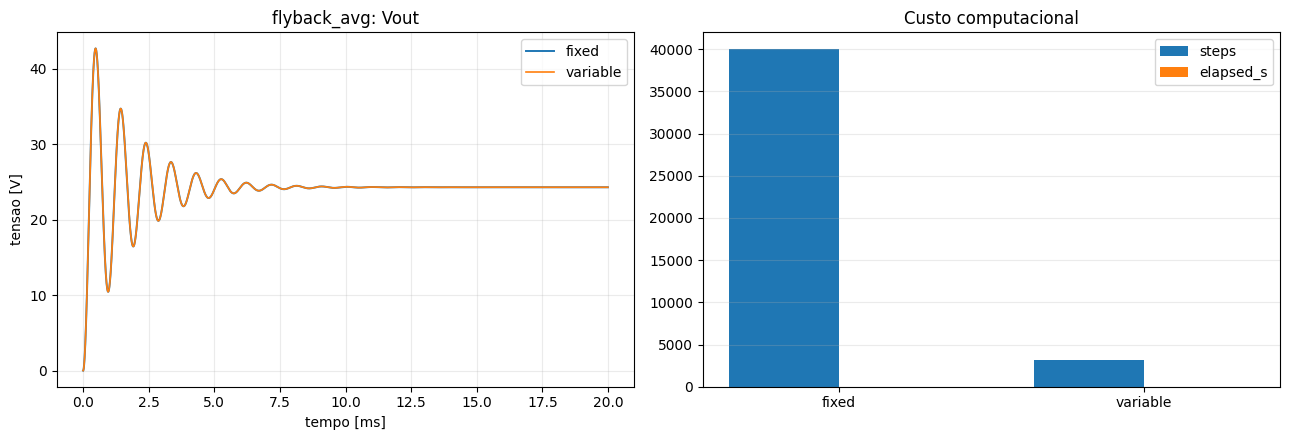

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

if base_fixed["success"]:
    ax[0].plot(base_fixed["time"] * 1e3, base_fixed["vout"], label="fixed", lw=1.4)
if base_variable["success"]:
    ax[0].plot(base_variable["time"] * 1e3, base_variable["vout"], label="variable", lw=1.2)

ax[0].set_title(f"{CONVERTER_ID}: Vout")
ax[0].set_xlabel("tempo [ms]")
ax[0].set_ylabel("tensao [V]")
ax[0].grid(True, alpha=0.25)
ax[0].legend()

labels = ["fixed", "variable"]
steps = [base_fixed["steps"], base_variable["steps"]]
elapsed = [base_fixed["elapsed_s"], base_variable["elapsed_s"]]

x = np.arange(len(labels))
bar_w = 0.36
ax[1].bar(x - bar_w/2, steps, width=bar_w, label="steps")
ax[1].bar(x + bar_w/2, elapsed, width=bar_w, label="elapsed_s")
ax[1].set_xticks(x)
ax[1].set_xticklabels(labels)
ax[1].set_title("Custo computacional")
ax[1].grid(True, axis="y", alpha=0.25)
ax[1].legend()

plt.tight_layout()
plt.show()


## 5) Campanha de estresse (pesada)

Executa varios cenarios de carga/duty/constantes de tempo para comparar convergencia e custo.


In [7]:
if STRESS_HEAVY:
    scenarios = [
        {"name": "S1", "duty_scale": 0.88, "load_scale": 0.70, "lc_scale": 0.70, "tstop_scale": 1.0},
        {"name": "S2", "duty_scale": 0.92, "load_scale": 0.85, "lc_scale": 0.85, "tstop_scale": 1.2},
        {"name": "S3", "duty_scale": 1.00, "load_scale": 1.00, "lc_scale": 1.00, "tstop_scale": 1.0},
        {"name": "S4", "duty_scale": 1.05, "load_scale": 1.20, "lc_scale": 1.10, "tstop_scale": 1.5},
        {"name": "S5", "duty_scale": 1.10, "load_scale": 1.35, "lc_scale": 1.30, "tstop_scale": 2.0},
        {"name": "S6", "duty_scale": 0.95, "load_scale": 0.60, "lc_scale": 1.20, "tstop_scale": 1.8},
    ]
else:
    scenarios = [
        {"name": "S1", "duty_scale": 1.0, "load_scale": 1.0, "lc_scale": 1.0, "tstop_scale": 1.0},
        {"name": "S2", "duty_scale": 1.05, "load_scale": 1.2, "lc_scale": 1.1, "tstop_scale": 1.2},
    ]

campaign_results = []
for sc in scenarios:
    for mode in ("fixed", "variable"):
        duty = float(np.clip(DUTY * sc["duty_scale"], 0.05, 0.90))
        rload = max(0.5, R_LOAD * sc["load_scale"])
        l_main = L_MAIN * sc["lc_scale"]
        c_main = C_MAIN * sc["lc_scale"]
        tstop = BASE_TSTOP * sc["tstop_scale"]

        result = run_case(
            step_mode=mode,
            vin=VIN,
            duty=duty,
            turns_ratio=TURNS_RATIO,
            L_main=l_main,
            C_main=c_main,
            R_load=rload,
            tstop=tstop,
            dt_fixed=BASE_DT_FIXED,
            rc_sections=RC_SECTIONS,
        )
        result["scenario"] = sc["name"]
        campaign_results.append(result)

print(f"Cenarios executados: {len(campaign_results)}")


Cenarios executados: 12


In [8]:
def summarize_mode(results, mode):
    data = [r for r in results if r["mode"] == mode]
    ok = [r for r in data if r["success"]]
    fail = [r for r in data if not r["success"]]

    success_rate = (len(ok) / max(1, len(data))) * 100.0
    med_elapsed = statistics.median([r["elapsed_s"] for r in data]) if data else float("nan")
    med_steps = statistics.median([r["steps"] for r in data]) if data else float("nan")
    med_rej = statistics.median([r["rejections"] for r in data]) if data else float("nan")

    return {
        "mode": mode,
        "n": len(data),
        "n_ok": len(ok),
        "n_fail": len(fail),
        "success_rate": success_rate,
        "median_elapsed_s": med_elapsed,
        "median_steps": med_steps,
        "median_rejections": med_rej,
    }


sum_fixed = summarize_mode(campaign_results, "fixed")
sum_variable = summarize_mode(campaign_results, "variable")

for s in (sum_fixed, sum_variable):
    print("=" * 72)
    print("mode:", s["mode"])
    print("casos:", s["n"], "ok:", s["n_ok"], "fail:", s["n_fail"], "success_rate:", f"{s['success_rate']:.1f}%")
    print("median_elapsed_s:", f"{s['median_elapsed_s']:.4f}")
    print("median_steps:", int(s["median_steps"]))
    print("median_rejections:", int(s["median_rejections"]))

if sum_fixed["n_ok"] > 0 and sum_variable["n_ok"] > 0:
    speedup = sum_fixed["median_elapsed_s"] / max(1e-12, sum_variable["median_elapsed_s"])
    step_reduction = sum_fixed["median_steps"] / max(1e-12, sum_variable["median_steps"])
    print("=" * 72)
    print(f"speedup mediano (fixed/variable): {speedup:.2f}x")
    print(f"reducao mediana de passos (fixed/variable): {step_reduction:.2f}x")


mode: fixed
casos: 6 ok: 6 fail: 0 success_rate: 100.0%
median_elapsed_s: 0.0352
median_steps: 54001
median_rejections: 0
mode: variable
casos: 6 ok: 6 fail: 0 success_rate: 100.0%
median_elapsed_s: 0.0052
median_steps: 3101
median_rejections: 2
speedup mediano (fixed/variable): 6.82x
reducao mediana de passos (fixed/variable): 17.41x


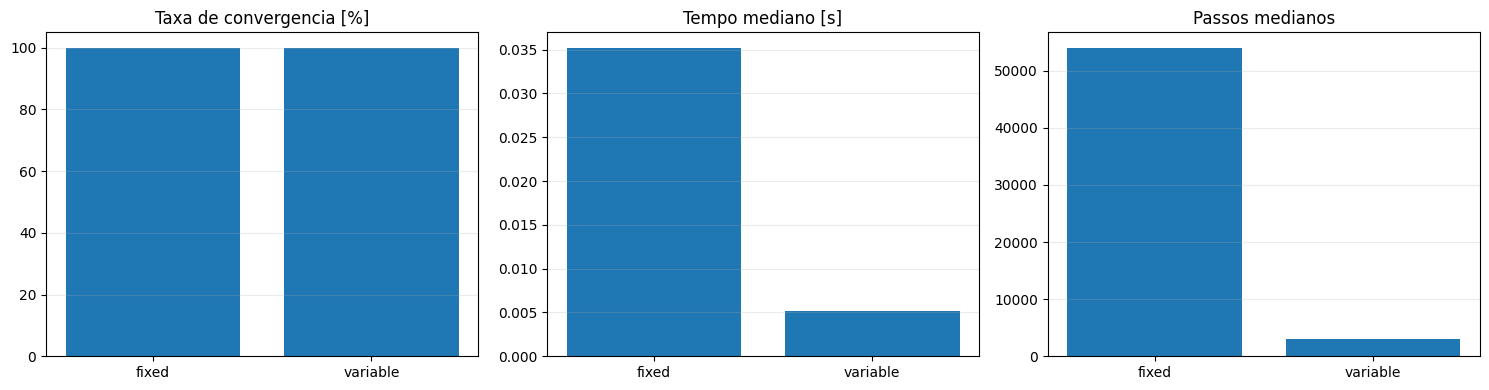

In [9]:
labels = ["fixed", "variable"]
summary = [sum_fixed, sum_variable]

success_rate = [s["success_rate"] for s in summary]
med_elapsed = [s["median_elapsed_s"] for s in summary]
med_steps = [s["median_steps"] for s in summary]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].bar(labels, success_rate)
ax[0].set_ylim([0, 105])
ax[0].set_title("Taxa de convergencia [%]")
ax[0].grid(True, axis="y", alpha=0.25)

ax[1].bar(labels, med_elapsed)
ax[1].set_title("Tempo mediano [s]")
ax[1].grid(True, axis="y", alpha=0.25)

ax[2].bar(labels, med_steps)
ax[2].set_title("Passos medianos")
ax[2].grid(True, axis="y", alpha=0.25)

plt.tight_layout()
plt.show()
